# Baseline Dense Retrieval vs. Cross-Encoder Re-Ranking
### RAG over India's *Digital Personal Data Protection Act, 2023*

This notebook builds two retrieval-augmented generation pipelines over **the same chunked copy** of
the DPDP Act and compares them.

| | Pipeline 1 — Baseline | Pipeline 2 — Re-ranking |
|---|---|---|
| Stage A | bi-encoder → top-10 by cosine similarity | *same* top-10 |
| Stage B | — | cross-encoder scores all 10 (query, chunk) pairs, re-sort |
| Context | top-3 of stage A | top-3 after re-sorting |
| Generator | LLM via Groq, shared prompt template | LLM via Groq, shared prompt template |

**Notebook map**
1. Setup & configuration
2. Reading the PDF
3. Structure-aware chunking
4. Vector store (bi-encoder + FAISS)
5. Retrieval and re-ranking functions
6. Grounded prompt and LLM
7. The two pipelines
8. Evaluation query set (gold-labelled)
9. Rank-shift analysis
10. Failure-mode showcases: Answer 1 vs Answer 2
11. Latency profiling and scaling
12. Export of results

## 1. Setup & configuration

All tunable values live in this one cell. They were fixed **before** any retrieval results were looked
at, so the failure cases later on are not produced by tuning the chunker against the queries.

`USE_TF=0` stops `transformers` from importing TensorFlow (the machine this was developed on has a
broken TensorFlow install; nothing here needs it).

In [1]:
import os
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import re, json, time, hashlib, random, statistics, textwrap, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fitz                      # PyMuPDF: PDF text with coordinates
import faiss                     # vector store
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder

# ---- paths
PDF_PATH  = Path("data/dpdp_act_2023.pdf")
PDF_URL   = "https://www.meity.gov.in/static/uploads/2024/06/2bf1f0e9f04e6fb4f8fef35e82c42aa5.pdf"
RESULTS   = Path("results")
FIGURES   = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# ---- models
BI_ENCODER_ID    = "sentence-transformers/all-MiniLM-L6-v2"     # 384-d, reads max 256 tokens
CROSS_ENCODER_ID = "cross-encoder/ms-marco-MiniLM-L-6-v2"       # reads max 512 tokens
LLM_MODEL_ID     = os.environ.get("LLM_MODEL", "openai/gpt-oss-120b")   # served by Groq

# ---- retrieval sizes (fixed by the assignment)
K_CANDIDATES = 10     # chunks pulled by the bi-encoder
K_CONTEXT    = 3      # chunks handed to the LLM

# ---- chunking
MAX_CHUNK_TOKENS = 200    # well below the bi-encoder's 256-token window, so nothing is truncated

# ---- latency profiling
TIMING_REPEATS = 30

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

# chart styling used by every figure
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

device: cuda | NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Reading the PDF

The official Gazette copy (21 pages) is used. Its layout matters for extraction:

* **Body text** sits in a column between x ≈ 117 and 478 pt. A new paragraph begins with an
  *indented* line; wrapped continuation lines start flush at the left edge.
* **Section titles** are printed as *margin notes* outside that column (left margin on even pages,
  right on odd pages). Some margin notes are not titles but citations of other Acts, e.g. `24 of 1997.`
* Every page has a running header (`THE GAZETTE OF INDIA EXTRAORDINARY`), page 1 has a bilingual
  masthead, and the last page has a printer's footer and a digital-signature stamp — all removed.
* **The Schedule** (penalty amounts) on the last page is a 3-column table. Reading it block by block
  would separate each breach from its penalty, so it is rebuilt row by row.

In [2]:
if not PDF_PATH.exists():                                  # fetch the official copy once
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(PDF_URL, PDF_PATH)

doc = fitz.open(PDF_PATH)
LAST_PAGE = doc.page_count                                 # the Schedule page
print(f"{PDF_PATH.name}: {doc.page_count} pages")

BODY_LEFT, BODY_RIGHT = 110, 482      # x-range (pt) of the main text column
HEADER_BOTTOM   = 90                  # running header lies above this y
MASTHEAD_BOTTOM = 500                 # page 1 masthead lies above this y
FOOTER_TEXT  = re.compile(r"^(UPLOADED BY|MGIPMRND|Digitally signed|Kshitiz Mohan|DR\. REETA)")
ACT_CITATION = re.compile(r"\s*\d+ of \d{4}\.$")
PARA_START   = re.compile(r"^(\d{1,2}\.\s|\(\w{1,5}\)|Illustrations?\.|Explanation|Provided|CHAPTER\b|[A-Z][A-Z ,]{5,}$)")


def tidy(text):
    return " ".join(text.split())


def is_noise(text, y0, page_no):
    # headers, masthead, footer, signature stamp and decorative glyph rows
    return (not text or y0 < HEADER_BOTTOM or (page_no == 1 and y0 < MASTHEAD_BOTTOM)
            or FOOTER_TEXT.match(text) is not None or re.fullmatch(r"[\W_]+", text) is not None)


def read_margin_titles(doc):
    # Margin notes = section titles, in reading order (top to bottom, page by page).
    titles = []
    for page_no in range(1, LAST_PAGE):
        blocks = sorted(doc[page_no - 1].get_text("blocks"), key=lambda b: b[1])
        for x0, y0, _, _, text, *_ in blocks:
            text = tidy(text)
            if is_noise(text, y0, page_no) or BODY_LEFT <= x0 <= BODY_RIGHT:
                continue
            title = ACT_CITATION.sub("", text).strip()     # drop "45 of 1860." style citations
            if title:
                titles.append(title.rstrip("."))
    return titles


def read_body_paragraphs(doc):
    # Rebuild paragraphs from individual lines, because PyMuPDF blocks sometimes merge several
    # paragraphs (e.g. an Illustration and the next section's first sentence) into one block.
    paragraphs = []
    for page_no in range(1, LAST_PAGE):
        lines = []
        for block in doc[page_no - 1].get_text("dict")["blocks"]:
            for line in block.get("lines", []):
                x0, y0 = line["bbox"][0], line["bbox"][1]
                text = tidy("".join(span["text"] for span in line["spans"]))
                if is_noise(text, y0, page_no) or not (BODY_LEFT <= x0 <= BODY_RIGHT):
                    continue
                lines.append((y0, x0, text))
        for y0, x0, text in sorted(lines):
            previous = paragraphs[-1]["text"] if paragraphs else ""
            indented = x0 > BODY_LEFT + 15
            new_paragraph = indented and (PARA_START.match(text) or re.search(r"[.;:—–]$", previous))
            if not paragraphs:
                paragraphs.append({"page": page_no, "text": text})
            elif new_paragraph and not re.fullmatch(r"Illustrations?\.", previous):
                paragraphs.append({"page": page_no, "text": text})
            else:                                        # continuation line (or text under a heading)
                joiner = "" if previous.endswith("-") else " "
                paragraphs[-1]["text"] = previous + joiner + text
                paragraphs[-1].setdefault("more_pages", set()).add(page_no)
    return paragraphs


def read_schedule_rows(page):
    # The Schedule table: Sl. No. | breach (x < 400) | penalty (x >= 400). Rows share a y position.
    rows = {}
    for x0, y0, _, _, text, *_ in page.get_text("blocks"):
        text = tidy(text)
        if not 190 < y0 < 550:            # skip the column headers above and the signature below
            continue
        column = "no" if x0 < 160 else ("breach" if x0 < 400 else "penalty")
        rows.setdefault(round(y0), {})[column] = text
    return [f"{r['no']} {r['breach']} Penalty: {r['penalty']}" for _, r in sorted(rows.items())]


margin_titles = read_margin_titles(doc)
paragraphs    = read_body_paragraphs(doc)
schedule_rows = read_schedule_rows(doc[LAST_PAGE - 1])

print(f"margin titles found : {len(margin_titles)}  (the Act has 44 sections)")
print(f"body paragraphs     : {len(paragraphs)}")
print(f"schedule rows       : {len(schedule_rows)}")
assert len(margin_titles) == 44, "every section should have exactly one margin title"

dpdp_act_2023.pdf: 21 pages
margin titles found : 44  (the Act has 44 sections)
body paragraphs     : 342
schedule rows       : 7


In [3]:
# Before / after cleaning, for one page: raw PyMuPDF text vs. the rebuilt paragraphs.
SAMPLE_PAGE = 5
print("RAW TEXT (first 700 characters)\n" + "-" * 40)
print(doc[SAMPLE_PAGE - 1].get_text()[:700])
print("\nREBUILT PARAGRAPHS\n" + "-" * 40)
for p in [p for p in paragraphs if p["page"] == SAMPLE_PAGE][:6]:
    print(textwrap.fill(p["text"], 110)[:400], "\n")
print("SCHEDULE ROWS\n" + "-" * 40)
for row in schedule_rows:
    print(textwrap.fill(row, 110))

RAW TEXT (first 700 characters)
----------------------------------------
SEC. 1]
THE GAZETTE OF INDIA EXTRAORDINARY
5
(b) the Data Fiduciary may continue to process the personal data until and
unless the Data Principal withdraws her consent.
Illustration.
X, an individual, gave her consent to the processing of her personal data for an online
shopping app or website operated by Y, an e-commerce service provider, before the
commencement of this Act. Upon commencement of the Act, Y shall, as soon as practicable,
give through email, in-app notification or other effective method information to X, describing
the personal data and the purpose of its processing.
(3) The Data Fiduciary shall give the Data Principal the option to access the contents
of the notice referred 

REBUILT PARAGRAPHS
----------------------------------------
(b) the Data Fiduciary may continue to process the personal data until and unless the Data Principal withdraws
her consent. 

Illustration. X, an individual, gave he

## 3. Structure-aware chunking

A legal text already comes in units: **Section → sub-section `(1)` → clause `(a)` → sub-clause `(i)`**.
Chunks follow those units instead of cutting at a fixed word count:

1. A section begins at a paragraph starting with its number (`6. (1) The consent…`). Numbers are
   matched in order (1, 2, 3, …), so a clause such as `(2)` or a list item `1.` cannot be mistaken
   for a new section. Chapter headings are tracked on the way.
2. Inside a section, paragraphs are packed into a chunk until the next one would exceed
   `MAX_CHUNK_TOKENS`. A new sub-section starts a fresh chunk once the current one is half full,
   so a rule tends to stay together with its own proviso/explanation.
3. A single paragraph that is still too long is split at sentence / clause punctuation.
4. Every chunk starts with `Section N – <title>.` so it stays interpretable (and citable) on its own.

Token counts use the **bi-encoder's own tokenizer**: anything beyond its 256-token window would be
silently dropped from the embedding.

In [4]:
def split_into_sections(paragraphs, titles, schedule_rows):
    sections, chapter, chapter_no, expect = [], "Preamble", None, 1
    for para in paragraphs:
        text = para["text"]
        if re.fullmatch(r"CHAPTER [IVXL]+", text):
            chapter_no = text
            continue
        if chapter_no:                                       # line right after "CHAPTER II"
            chapter, chapter_no = f"{chapter_no} – {text.capitalize()}", None
            continue
        pages = {para["page"]} | para.get("more_pages", set())
        number = re.match(r"(\d{1,2})\.\s", text)
        if number and int(number.group(1)) == expect:
            sections.append({"section": str(expect), "title": titles[expect - 1], "chapter": chapter,
                             "pages": pages, "paragraphs": [text]})
            expect += 1
        elif sections:                                       # skip the long title before section 1
            sections[-1]["paragraphs"].append(text)
            sections[-1]["pages"] |= pages
    sections.append({"section": "Schedule", "title": "Penalties (see section 33(1))",
                     "chapter": "The Schedule", "pages": {LAST_PAGE}, "paragraphs": schedule_rows})
    return sections


bi_tokenizer = SentenceTransformer(BI_ENCODER_ID, device="cpu").tokenizer
count_tokens = lambda text: len(bi_tokenizer.tokenize(text))


def make_chunks(sections, max_tokens=MAX_CHUNK_TOKENS):
    chunks = []
    for sec in sections:
        header = (f"Section {sec['section']} – {sec['title']}." if sec["section"] != "Schedule"
                  else "The Schedule – Penalties (see section 33(1)).")
        budget = max_tokens - count_tokens(header) - 1
        pieces = []
        for para in sec["paragraphs"]:                     # break over-long paragraphs first
            if count_tokens(para) <= budget:
                pieces.append(para)
            else:
                pieces.extend(re.split(r"(?<=[.;:—])\s+", para))

        current, used = [], 0
        def close():
            if current:
                chunks.append({"chunk_id": len(chunks), "section": sec["section"], "title": sec["title"],
                               "chapter": sec["chapter"], "pages": sorted(sec["pages"]),
                               "text": header + " " + " ".join(current)})
        for piece in pieces:
            n = count_tokens(piece)
            starts_subsection = re.match(r"\(\d+\)", piece) is not None
            if current and (used + n > budget or (starts_subsection and used > budget / 2)):
                close()
                current, used = [], 0
            current.append(piece)
            used += n
        close()
    return chunks


sections = split_into_sections(paragraphs, margin_titles, schedule_rows)
chunks   = make_chunks(sections)
token_lengths = np.array([count_tokens(c["text"]) for c in chunks])

print(f"sections: {len(sections)}   chunks: {len(chunks)}")
print(f"tokens per chunk: min {token_lengths.min()}, median {int(np.median(token_lengths))}, max {token_lengths.max()}")
assert len(sections) == 45                                   # 44 sections + the Schedule
assert token_lengths.max() <= 254, "a chunk would be truncated by the bi-encoder"
assert all(c["chunk_id"] == i for i, c in enumerate(chunks))

pd.DataFrame(chunks)[["chunk_id", "section", "title", "chapter", "pages"]].head(12)

sections: 45   chunks: 105
tokens per chunk: min 28, median 132, max 197


,chunk_id,section,title,chapter,pages
0,0,1,Short title and commencement,CHAPTER I – Preliminary,[1]
1,1,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
2,2,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
3,3,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
4,4,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
5,5,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
6,6,2,Definitions,CHAPTER I – Preliminary,"[2, 3]"
7,7,3,Application of Act,CHAPTER I – Preliminary,"[3, 4]"
8,8,3,Application of Act,CHAPTER I – Preliminary,"[3, 4]"
9,9,4,Grounds for processing personal data,CHAPTER II – Obligations of data fiduciary,[4]


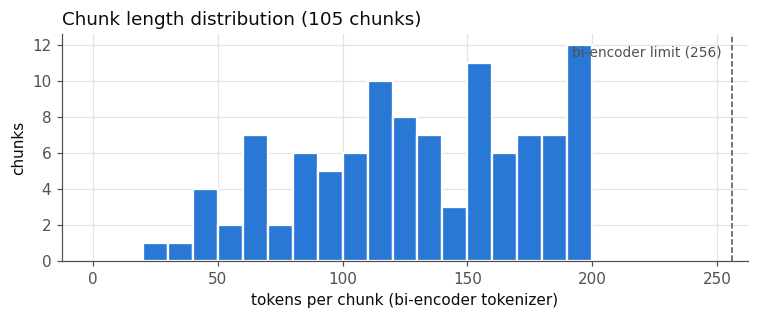

Section 8 – General obligations of Data Fiduciary. (5) A Data Fiduciary shall protect personal data in its possession or under its control, including in respect of any processing undertaken by it or on its behalf by a Data Processor, by taking reasonable security safeguards to prevent personal data breach. (6) In the event of a personal data breach, the Data Fiduciary shall give the Board and each affected Data Principal, intimation of such breach in such form and manner as may be prescribed.


In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(token_lengths, bins=range(0, 260, 10), color=BLUE, edgecolor="white", linewidth=1.5)
ax.axvline(256, color=MUTED, linestyle="--", linewidth=1)
ax.text(252, ax.get_ylim()[1] * 0.9, "bi-encoder limit (256)", ha="right", color=MUTED, fontsize=9)
ax.set_xlabel("tokens per chunk (bi-encoder tokenizer)")
ax.set_ylabel("chunks")
ax.set_title(f"Chunk length distribution ({len(chunks)} chunks)", loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "chunk_token_lengths.png", bbox_inches="tight"); plt.show()

print(chunks[28]["text"][:600])

## 4. Vector store: bi-encoder embeddings in FAISS

Each chunk is embedded **once, offline**, by the bi-encoder. Vectors are L2-normalised, so the inner
product computed by `faiss.IndexFlatIP` *is* the cosine similarity. `IndexFlatIP` is an exact
(brute-force) index: with ~100 chunks there is no reason to accept the recall loss of an approximate
index, and it means every ranking error below is the encoder's, not the index's.

In [6]:
bi_encoder = SentenceTransformer(BI_ENCODER_ID, device=DEVICE)


def embed(texts, model=None):
    model = model or bi_encoder
    return model.encode(texts, normalize_embeddings=True, convert_to_numpy=True,
                        batch_size=32, show_progress_bar=False).astype("float32")


chunk_vectors = embed([c["text"] for c in chunks])
vector_store = faiss.IndexFlatIP(chunk_vectors.shape[1])
vector_store.add(chunk_vectors)
print(f"vector store: {vector_store.ntotal} vectors x {vector_store.d} dims")
print("norms ≈ 1:", np.allclose(np.linalg.norm(chunk_vectors, axis=1), 1, atol=1e-4))

vector store: 105 vectors x 384 dims
norms ≈ 1: True


## 5. Retrieval and re-ranking

* `dense_top_k` — **stage A**, shared by both pipelines: embed the query with the same bi-encoder
  and take the `K_CANDIDATES = 10` nearest chunks. Each candidate remembers its bi-encoder score and rank.
* `cross_rerank` — **stage B**, pipeline 2 only: the cross-encoder reads each (query, chunk) pair
  *together* in one forward pass and outputs a relevance logit. All 10 pairs go through in a single
  batch; candidates are re-sorted by that score and get a new rank, keeping the old one for analysis.

In [7]:
cross_encoder = CrossEncoder(CROSS_ENCODER_ID, device=DEVICE)


def dense_top_k(query, k=K_CANDIDATES, model=None):
    scores, ids = vector_store.search(embed([query], model), k)
    return [{"chunk_id": int(cid), "bi_score": float(score), "bi_rank": rank}
            for rank, (score, cid) in enumerate(zip(scores[0], ids[0]), start=1)]


def cross_rerank(query, candidates, model=None):
    model = model or cross_encoder
    pairs = [(query, chunks[c["chunk_id"]]["text"]) for c in candidates]
    logits = model.predict(pairs, batch_size=len(pairs), show_progress_bar=False)
    rescored = [{**c, "ce_score": float(s)} for c, s in zip(candidates, logits)]
    rescored.sort(key=lambda c: c["ce_score"], reverse=True)
    for rank, c in enumerate(rescored, start=1):
        c["ce_rank"] = rank
    return rescored


def show_candidates(query, reranked):
    # one row per candidate: where the bi-encoder put it and where the cross-encoder put it
    rows = [{"bi_rank": c["bi_rank"], "ce_rank": c["ce_rank"], "chunk": c["chunk_id"],
             "section": chunks[c["chunk_id"]]["section"], "bi_score": round(c["bi_score"], 3),
             "ce_score": round(c["ce_score"], 2), "text": chunks[c["chunk_id"]]["text"][:90] + "…"}
            for c in reranked]
    return pd.DataFrame(rows).sort_values("bi_rank").set_index("bi_rank")


probe = "Can a company keep personal data forever?"
show_candidates(probe, cross_rerank(probe, dense_top_k(probe)))

,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,1,29,8,0.577,0.13,Section 8 – General obligations of Data Fiduci...
2,2,41,12,0.522,-0.36,Section 12 – Right to correction and erasure o...
3,4,30,8,0.520,-1.28,Section 8 – General obligations of Data Fiduci...
4,8,21,7,0.517,-5.24,Section 7 – Certain legitimate uses. 7. A Data...
5,7,39,11,0.485,-4.60,Section 11 – Right to access information about...
6,6,40,12,0.476,-3.62,Section 12 – Right to correction and erasure o...
7,3,19,6,0.476,-0.50,Section 6 – Consent. (6) If a Data Principal w...
8,9,31,8,0.452,-7.03,Section 8 – General obligations of Data Fiduci...
9,10,11,5,0.450,-7.14,"Section 5 – Notice. Illustration. X, an indivi..."


## 6. Grounded prompt and LLM

Both pipelines use **one** prompt builder, so the only thing that differs between Answer 1 and
Answer 2 is which three extracts were retrieved. The prompt follows the grounded-generation layout:
instruction → labelled, delimited evidence → refusal rule → citation rule → question last.
The refusal rule matters for this experiment: without it, a model given the wrong extracts would
quietly answer from its own memory and hide the retrieval failure.

Generation uses `openai/gpt-oss-120b` served by the Groq API, at temperature 0 with low reasoning effort
(the model's reasoning text is not included in the answer). Every answer is cached in
`results/llm_cache.json` (keyed by model +
exact prompt), so re-running the notebook gives identical answers and does not spend API quota.

In [8]:
PROMPT_TEMPLATE = '''You answer questions about India's Digital Personal Data Protection Act, 2023 (DPDP Act).
Use ONLY the numbered extracts from the Act below. Do not use any outside knowledge.

=== EXTRACTS ===
{evidence}
=== END OF EXTRACTS ===

Rules:
1. If the extracts do not contain the answer, reply exactly: "The provided extracts do not answer this question."
2. If they answer it only in part, give the part they support and say what is missing.
3. Cite the extract number after every claim, like [S1].
4. Answer in at most 120 words.

Question: {question}
Answer:'''


def build_prompt(question, passages):
    evidence = "\n\n".join(f"[S{i}] {chunks[p['chunk_id']]['text']}" for i, p in enumerate(passages, start=1))
    return PROMPT_TEMPLATE.format(evidence=evidence, question=question)

In [9]:
from groq import Groq


def load_env_file(*candidates):
    # Reads KEY=value or "KEY : value" lines from the first .env found (the file is never committed).
    for path in map(Path, candidates):
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                match = re.match(r"\s*([^=:#]+?)\s*[=:]\s*(.+?)\s*$", line)
                if match:
                    name = re.sub(r"\W+", "_", match.group(1).strip()).upper()
                    os.environ.setdefault(name, match.group(2).strip().strip("'\""))
            return path
    return None


env_path = load_env_file(".env", "../.env")
GROQ_KEY = os.environ.get("GROQ_API_KEY")
llm_client = Groq(api_key=GROQ_KEY) if GROQ_KEY else None
LLM_CACHE_PATH = RESULTS / "llm_cache.json"
llm_cache = json.loads(LLM_CACHE_PATH.read_text(encoding="utf-8")) if LLM_CACHE_PATH.exists() else {}
print(f"Groq key found ({env_path})" if GROQ_KEY else "GROQ_API_KEY not set: only cached answers can be shown")
print("model:", LLM_MODEL_ID, "| cached answers:", len(llm_cache))


def ask_llm(prompt, max_attempts=6):
    # Returns (answer, seconds). Cached answers keep the time measured when they were generated.
    key = hashlib.sha256(f"{LLM_MODEL_ID}|{prompt}".encode("utf-8")).hexdigest()
    if key in llm_cache:
        return llm_cache[key]["answer"], llm_cache[key]["seconds"]
    if llm_client is None:
        return None, None
    request = {"model": LLM_MODEL_ID, "messages": [{"role": "user", "content": prompt}],
               "temperature": 0.0, "max_completion_tokens": 1024}
    if "gpt-oss" in LLM_MODEL_ID:            # reasoning model: keep reasoning short and out of the answer
        request.update(reasoning_effort="low", include_reasoning=False)
    for attempt in range(max_attempts):
        try:
            start = time.perf_counter()
            reply = llm_client.chat.completions.create(**request)
            seconds = time.perf_counter() - start
            break
        except Exception as err:             # free tier: back off on rate limits / overload
            if attempt == max_attempts - 1 or not re.search(r"429|503|rate.?limit|over capacity", str(err), re.I):
                raise
            time.sleep(min(60, 5 * 2 ** attempt))
    answer = (reply.choices[0].message.content or "").strip()
    llm_cache[key] = {"model": LLM_MODEL_ID, "answer": answer, "seconds": round(seconds, 3)}
    LLM_CACHE_PATH.write_text(json.dumps(llm_cache, ensure_ascii=False, indent=1), encoding="utf-8")
    return answer, seconds

Groq key found (.env)
model: openai/gpt-oss-120b | cached answers: 63


## 7. The two pipelines

`run_baseline` and `run_rerank` return the same record shape: top-10, top-3, prompt, answer and
per-stage timings. Both start with the identical `dense_top_k` call; the re-ranking pipeline only
re-orders that list.

In [10]:
def timed(fn, *args):
    start = time.perf_counter()
    out = fn(*args)
    return out, time.perf_counter() - start


def run_baseline(query, generate=True):
    candidates, t_dense = timed(dense_top_k, query)
    context = candidates[:K_CONTEXT]
    prompt = build_prompt(query, context)
    answer, t_llm = ask_llm(prompt) if generate else (None, None)
    return {"pipeline": "baseline", "query": query, "top10": candidates, "top3": context,
            "prompt": prompt, "answer": answer,
            "timings": {"retrieve_s": t_dense, "rerank_s": 0.0, "llm_s": t_llm}}


def run_rerank(query, generate=True):
    candidates, t_dense = timed(dense_top_k, query)
    reranked, t_rerank = timed(cross_rerank, query, candidates)
    context = reranked[:K_CONTEXT]
    prompt = build_prompt(query, context)
    answer, t_llm = ask_llm(prompt) if generate else (None, None)
    return {"pipeline": "rerank", "query": query, "top10": reranked, "top3": context,
            "prompt": prompt, "answer": answer,
            "timings": {"retrieve_s": t_dense, "rerank_s": t_rerank, "llm_s": t_llm}}


demo_1, demo_2 = run_baseline(probe, generate=False), run_rerank(probe, generate=False)
assert {c["chunk_id"] for c in demo_1["top10"]} == {c["chunk_id"] for c in demo_2["top10"]}
print("baseline top-3:", [c["chunk_id"] for c in demo_1["top3"]])
print("re-rank  top-3:", [c["chunk_id"] for c in demo_2["top3"]])
print("\n" + demo_1["prompt"][:900] + " …")

baseline top-3: [29, 41, 30]
re-rank  top-3: [29, 41, 19]

You answer questions about India's Digital Personal Data Protection Act, 2023 (DPDP Act).
Use ONLY the numbered extracts from the Act below. Do not use any outside knowledge.

=== EXTRACTS ===
[S1] Section 8 – General obligations of Data Fiduciary. (7) A Data Fiduciary shall, unless retention is necessary for compliance with any law for the time being in force,— (a) erase personal data, upon the Data Principal withdrawing her consent or as soon as it is reasonable to assume that the specified purpose is no longer being served, whichever is earlier; and (b) cause its Data Processor to erase any personal data that was made available by the Data Fiduciary for processing to such Data Processor. Illustrations. (I) X, an individual, registers herself on an online marketplace operated by Y, an e-commerce service provider. X gives her consent to Y for the processing of her personal data for sell …


## 8. Evaluation query set

Questions phrased the way a non-lawyer would ask them (so they often do **not** reuse the
Act's vocabulary). They were written and labelled before running retrieval. Each question has:

* `category` — the failure family it probes (from the assignment):
  *Keyword trap / synonym*, *Exception / penalty elsewhere*, *Negation / constraint*, *Other*.
* `gold` — one or more short phrases copied from the Act; every chunk containing one of them is a
  **gold chunk** (the chunk that actually answers the question). Using phrases instead of raw chunk
  ids keeps the labels valid even if the chunker changes.
* `reference` — the correct answer with its section, used to judge Answer 1 and Answer 2.

**Two batches.** Batch 1 (Q01–Q20) was written before any retrieval was run. It produced only one query
where re-ranking moved the gold chunk into the top-3, while the assignment asks for at least two. As
decided up front, the fix was to *add* more realistic questions (batch 2, Q21–Q32), not to change the
chunking or the models. Batch 2 was also written before being run, and no batch-1 query was removed or
reworded. The `batch` column keeps this visible in every table.

In [11]:
QUERIES = [
    # ---- Exception / penalty located elsewhere: the duty is in one section, the penalty in the Schedule
    ("Q01", "Exception / penalty elsewhere",
     "What is the maximum fine a company can face if weak security leads to a leak of its customers' personal data?",
     ["two hundred and fifty crore"],
     "Up to Rs 250 crore for failing to take reasonable security safeguards under s.8(5) (Schedule, item 1)."),
    ("Q02", "Exception / penalty elsewhere",
     "How much can an ordinary person be fined for making a fake complaint against a company?",
     ["ten thousand rupees"],
     "s.15(d) bars false or frivolous grievances; breach of a Data Principal's duties: up to Rs 10,000 (Schedule, item 5)."),
    ("Q03", "Exception / penalty elsewhere",
     "What is the penalty for a company that does not report a data breach to the Board?",
     ["two hundred crore"],
     "Up to Rs 200 crore for not notifying the Board / affected persons under s.8(6) (Schedule, item 2)."),
    ("Q04", "Exception / penalty elsewhere",
     "Does this law cover phone numbers I save on my phone for my own personal use?",
     ["personal or domestic purpose"],
     "No. s.3(c)(i): the Act does not apply to personal data processed by an individual for a personal or domestic purpose."),
    ("Q05", "Exception / penalty elsewhere",
     "Can a startup skip giving its users a privacy notice?",
     ["including startups"],
     "Only if notified: s.17(3) lets the Government exempt notified Data Fiduciaries, including startups, from s.5 (notice), s.8(3), 8(7), s.10 and s.11."),
    ("Q06", "Exception / penalty elsewhere",
     "Does a company still need my consent if the police are investigating a crime involving my data?",
     ["prevention, detection, investigation or prosecution"],
     "No. s.17(1)(c): Chapter II (except s.8(1) and 8(5)), Chapter III and s.16 do not apply to processing for prevention, detection, investigation or prosecution of offences."),
    ("Q07", "Exception / penalty elsewhere",
     "Can my data be used without my consent for a research study?",
     ["research, archiving or statistical"],
     "s.17(2)(b): the Act does not apply to processing for research, archiving or statistical purposes if the data is not used for decisions specific to the person and prescribed standards are followed."),

    # ---- Negation / constraint: the answer is a "shall not" / "only" rule
    ("Q08", "Negation / constraint",
     "Is an app allowed to show personalised ads to a 15-year-old user?",
     ["targeted advertising directed at children"],
     "No. s.9(3) prohibits tracking, behavioural monitoring and targeted advertising directed at children (under 18, s.2(f)); exceptions only as prescribed under s.9(4)."),
    ("Q09", "Negation / constraint",
     "Does a Data Protection Officer have to be located in India?",
     ["(ii) be based in India"],
     "Yes. s.10(2)(a)(ii): the DPO of a Significant Data Fiduciary must be based in India."),
    ("Q10", "Negation / constraint",
     "Can a company hand my data to an outside vendor for processing without any contract?",
     ["valid contract"],
     "No. s.8(2): a Data Fiduciary may engage a Data Processor only under a valid contract."),
    ("Q11", "Negation / constraint",
     "Can I sue a company in a civil court over misuse of my personal data?",
     ["No civil court shall have"],
     "No. s.39 bars civil courts from matters the Board is empowered to decide; complaints go to the Board (appeal to the Appellate Tribunal)."),
    ("Q12", "Negation / constraint",
     "Am I allowed to pretend to be someone else when giving my personal data to a service?",
     ["impersonate another person"],
     "No. s.15(b): a Data Principal must not impersonate another person; breach of duties can draw up to Rs 10,000."),

    # ---- Keyword trap / synonym: the query and the answer use different words
    ("Q13", "Keyword trap / synonym",
     "Can I take back my permission after I have agreed to let a company use my data?",
     ["right to withdraw her consent"],
     "Yes. s.6(4): consent can be withdrawn at any time, as easily as it was given; earlier processing stays lawful (s.6(5))."),
    ("Q14", "Keyword trap / synonym",
     "If hackers steal user data, who does the company have to inform?",
     ["intimation of such breach"],
     "s.8(6): the Board and each affected Data Principal, in the prescribed form and manner."),
    ("Q15", "Keyword trap / synonym",
     "What happens to my data rights after I die?",
     ["right to nominate"],
     "s.14: a Data Principal may nominate another individual to exercise her rights in the event of death or incapacity."),
    ("Q16", "Keyword trap / synonym",
     "Whose permission is needed before a website collects data about a child?",
     ["verifiable consent of the parent"],
     "s.9(1): verifiable consent of the parent or lawful guardian."),

    # ---- Other document-specific questions
    ("Q17", "Other",
     "How many days do I get to appeal against an order of the Data Protection Board?",
     ["sixty days"],
     "s.29(2): sixty days from receipt of the order, before the Appellate Tribunal (late appeals allowed for sufficient cause)."),
    ("Q18", "Other",
     "Can my personal data be stored on servers in a foreign country?",
     ["restrict the transfer"],
     "Yes, unless the Government restricts transfer to a notified country (s.16(1)); stricter sector laws still apply (s.16(2))."),
    ("Q19", "Other",
     "How long can a company keep my data after I delete my account?",
     ["unless retention is necessary"],
     "s.8(7): it must erase the data once consent is withdrawn or the purpose is no longer served, unless the law requires retention."),
    ("Q20", "Other",
     "What factors does the Board consider when deciding how big a fine should be?",
     ["nature, gravity and duration"],
     "s.33(2): nature, gravity and duration of the breach, type of data, repetitiveness, gain/loss, mitigation, proportionality and likely impact."),
]


# ---- Batch 2: written after batch 1 produced only one "fixed" case (see the note above this cell).
# Same chunks, same models, same settings; these queries were written before being run.
QUERIES_BATCH_2 = [
    ("Q21", "Negation / constraint",
     "Can a company refuse me a service just because I won't agree to share data it doesn't actually need?",
     ["limited to such personal data as is necessary"],
     "Consent must be limited to data necessary for the specified purpose (s.6(1)); consent to extra data is not required for the service (see the telemedicine illustration)."),
    ("Q22", "Keyword trap / synonym",
     "Can I ask a company to fix wrong information it holds about me?",
     ["right to correction, completion, updating and erasure"],
     "Yes. s.12(1)-(2): right to correction, completion, updating and erasure; the Data Fiduciary must correct inaccurate or misleading data."),
    ("Q23", "Exception / penalty elsewhere",
     "Can I go straight to the Data Protection Board with a complaint, or do I have to complain to the company first?",
     ["exhaust the opportunity of redressing"],
     "s.13(3): the Data Principal must first exhaust the company's grievance redressal before approaching the Board."),
    ("Q24", "Exception / penalty elsewhere",
     "Does the law protect information I have posted publicly on my blog or social media?",
     ["made or caused to be made publicly available", "while blogging her views"],
     "No. s.3(c)(ii): the Act does not apply to personal data made publicly available by the Data Principal herself."),
    ("Q25", "Keyword trap / synonym",
     "If I have not used an app for years, does the company have to delete my data?",
     ["deemed to no longer be served"],
     "s.8(8): the purpose is deemed no longer served if the person does not approach the company for the prescribed period; the data must then be erased (s.8(7))."),
    ("Q26", "Exception / penalty elsewhere",
     "If I send my details to a company myself for a particular purpose, does it still need my formal consent?",
     ["voluntarily provided her personal data"],
     "No. s.7(a): data voluntarily provided for a specified purpose, without indicating objection, may be processed for that purpose as a legitimate use."),
    ("Q27", "Exception / penalty elsewhere",
     "Do government departments also have to erase my data once the purpose is over?",
     ["In respect of processing by the State or any instrumentality"],
     "No. s.17(4): s.8(7) (erasure) and s.12(3) do not apply to processing by the State or its instrumentalities."),
    ("Q28", "Exception / penalty elsewhere",
     "Will a company tell me which other organisations it shared my data with, even if it shared it with an investigating agency?",
     ["Nothing contained in clause (b) or clause (c) of sub-section (1)"],
     "Not always. s.11(1)(b) gives the right to know with whom data was shared, but s.11(2) excludes sharing with Data Fiduciaries authorised by law for prevention/detection/investigation of offences."),
    ("Q29", "Negation / constraint",
     "Can the Data Protection Board seize a company's computers during an inquiry?",
     ["shall not prevent access to any premises"],
     "Generally no. s.28(8): the Board shall not take custody of equipment or items that may adversely affect the day-to-day functioning of a person."),
    ("Q30", "Exception / penalty elsewhere",
     "Can my employer use my personal data without asking for my consent?",
     ["purposes of employment"],
     "Yes, for employment purposes or safeguarding the employer from loss or liability: a legitimate use under s.7(i)."),
    ("Q31", "Negation / constraint",
     "Can the government remove a member of the Data Protection Board without giving them a hearing?",
     ["shall not be removed from her office"],
     "No. s.21(2): a Chairperson or Member cannot be removed unless given an opportunity of being heard."),
    ("Q32", "Other",
     "What can the government do if a company keeps getting fined and the Board recommends blocking it?",
     ["blocking for access by the public"],
     "s.37(1): on a Board reference (penalty imposed in two or more instances) and advice to block, the Government may order blocking of public access to the company's information."),
]


def gold_chunk_ids(phrases):
    return sorted({c["chunk_id"] for c in chunks for p in phrases if p.lower() in c["text"].lower()})


queries = pd.DataFrame([(*q, 1) for q in QUERIES] + [(*q, 2) for q in QUERIES_BATCH_2],
                       columns=["qid", "category", "query", "gold", "reference", "batch"])
queries["gold_chunks"] = queries["gold"].apply(gold_chunk_ids)
missing = queries[queries["gold_chunks"].str.len() == 0]
assert missing.empty, f"gold phrase not found for: {list(missing.qid)}"
queries[["qid", "batch", "category", "query", "gold_chunks"]]

,qid,batch,category,query,gold_chunks
0,Q01,1,Exception / penalty elsewhere,What is the maximum fine a company can face if...,[103]
1,Q02,1,Exception / penalty elsewhere,How much can an ordinary person be fined for m...,[103]
2,Q03,1,Exception / penalty elsewhere,What is the penalty for a company that does no...,[103]
3,Q04,1,Exception / penalty elsewhere,Does this law cover phone numbers I save on my...,[7]
4,Q05,1,Exception / penalty elsewhere,Can a startup skip giving its users a privacy ...,[51]
5,Q06,1,Exception / penalty elsewhere,Does a company still need my consent if the po...,[47]
6,Q07,1,Exception / penalty elsewhere,Can my data be used without my consent for a r...,[50]
7,Q08,1,Negation / constraint,Is an app allowed to show personalised ads to ...,[34]
8,Q09,1,Negation / constraint,Does a Data Protection Officer have to be loca...,[36]
9,Q10,1,Negation / constraint,Can a company hand my data to an outside vendo...,[26]


## 9. Rank-shift analysis

For every query both pipelines retrieve (no LLM yet) and we record where the **best-ranked gold chunk**
sits before and after re-ranking.

* **Hit@3** — is a gold chunk among the 3 chunks the LLM will see?
* **MRR@10** — mean of 1/rank of the first gold chunk in the top 10 (0 if it is not there).
* **Outcome** — `fixed` (outside top-3 → inside), `hurt` (inside → outside), `both hit`,
  `both miss`, or `not retrieved` (gold not in the top-10 at all: re-ranking cannot help, because it
  only re-orders what stage A returned).

In [12]:
def best_rank(ranked, gold, key):
    ranks = [c[key] for c in ranked if c["chunk_id"] in gold]
    return min(ranks) if ranks else None


def outcome(b, r):
    if b is None:
        return "not retrieved"
    if b > K_CONTEXT and r <= K_CONTEXT:
        return "fixed"
    if b <= K_CONTEXT and r > K_CONTEXT:
        return "hurt"
    return "both hit" if b <= K_CONTEXT else "both miss"


retrieval = {}          # qid -> (baseline record, rerank record) without LLM answers
rows = []
for q in queries.itertuples():
    base, rr = run_baseline(q.query, generate=False), run_rerank(q.query, generate=False)
    assert [c["chunk_id"] for c in base["top10"]] == [c["chunk_id"] for c in sorted(rr["top10"], key=lambda c: c["bi_rank"])]
    retrieval[q.qid] = (base, rr)
    gold = set(q.gold_chunks)
    b, r = best_rank(base["top10"], gold, "bi_rank"), best_rank(rr["top10"], gold, "ce_rank")
    rows.append({"qid": q.qid, "batch": q.batch, "category": q.category, "gold_chunks": q.gold_chunks,
                 "baseline_rank": b, "reranked_rank": r, "outcome": outcome(b, r),
                 "baseline_top3": [c["chunk_id"] for c in base["top3"]],
                 "reranked_top3": [c["chunk_id"] for c in rr["top3"]]})

rank_shift = pd.DataFrame(rows).set_index("qid")
rank_shift["baseline_rank"] = rank_shift["baseline_rank"].astype("Int64")
rank_shift["reranked_rank"] = rank_shift["reranked_rank"].astype("Int64")
rank_shift

,batch,category,gold_chunks,baseline_rank,reranked_rank,outcome,baseline_top3,reranked_top3
qid,,,,,,,,
Q01,1,Exception / penalty elsewhere,[103],3,1,both hit,"[66, 28, 103]","[103, 28, 66]"
Q02,1,Exception / penalty elsewhere,[103],3,2,both hit,"[104, 82, 103]","[104, 103, 73]"
Q03,1,Exception / penalty elsewhere,[103],3,1,both hit,"[82, 66, 103]","[103, 66, 67]"
Q04,1,Exception / penalty elsewhere,[7],9,9,both miss,"[14, 21, 19]","[21, 14, 19]"
Q05,1,Exception / penalty elsewhere,[51],1,1,both hit,"[51, 11, 12]","[51, 12, 11]"
Q06,1,Exception / penalty elsewhere,[47],<NA>,<NA>,not retrieved,"[20, 93, 19]","[17, 19, 14]"
Q07,1,Exception / penalty elsewhere,[50],<NA>,<NA>,not retrieved,"[17, 20, 33]","[17, 19, 14]"
Q08,1,Negation / constraint,[34],2,1,both hit,"[8, 34, 18]","[34, 18, 23]"
Q09,1,Negation / constraint,[36],5,1,fixed,"[46, 47, 7]","[36, 46, 47]"


In [13]:
def mrr(ranks):
    return float(np.mean([1 / r if pd.notna(r) else 0.0 for r in ranks]))


def hit_at(ranks, k):
    return float(np.mean([pd.notna(r) and r <= k for r in ranks]))


metric_rows = []
for name, column in [("Baseline (bi-encoder)", "baseline_rank"), ("Re-ranked (cross-encoder)", "reranked_rank")]:
    ranks = rank_shift[column]
    metric_rows.append({"pipeline": name, "Hit@1": hit_at(ranks, 1), "Hit@3": hit_at(ranks, 3),
                        "Recall@10": hit_at(ranks, 10), "MRR@10": mrr(ranks)})
metrics = pd.DataFrame(metric_rows).set_index("pipeline").round(3)
display(metrics)

print("Outcomes:", rank_shift["outcome"].value_counts().to_dict())
display(pd.crosstab(rank_shift["category"], rank_shift["outcome"]))

,Hit@1,Hit@3,Recall@10,MRR@10
pipeline,,,,
Baseline (bi-encoder),0.312,0.562,0.75,0.453
Re-ranked (cross-encoder),0.438,0.656,0.75,0.552


Outcomes: {'both hit': 17, 'not retrieved': 8, 'fixed': 4, 'both miss': 2, 'hurt': 1}


outcome,both hit,both miss,fixed,hurt,not retrieved
category,,,,,
Exception / penalty elsewhere,6,2,0,0,5
Keyword trap / synonym,3,0,2,0,1
Negation / constraint,3,0,2,1,2
Other,5,0,0,0,0


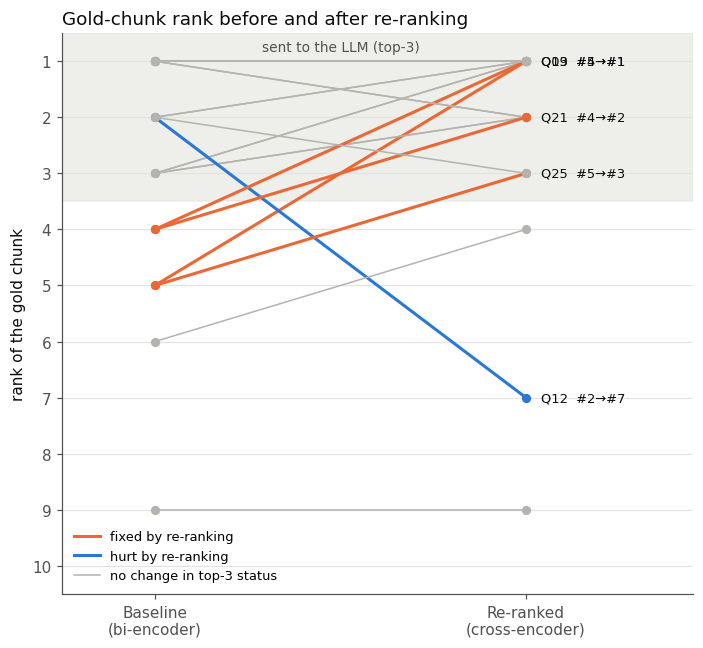

In [14]:
# Slope chart: each line is one query, from its gold chunk's baseline rank to its re-ranked rank.
plot = rank_shift.dropna(subset=["baseline_rank"])
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.axhspan(0.5, K_CONTEXT + 0.5, color=GRID, alpha=0.6, zorder=0)
ax.text(0.5, 0.62, "sent to the LLM (top-3)", ha="center", va="top", color=MUTED, fontsize=9)
for qid, row in plot.iterrows():
    b, r = int(row.baseline_rank), int(row.reranked_rank)
    colour = ORANGE if row.outcome == "fixed" else (BLUE if row.outcome == "hurt" else "#b5b3ad")
    width = 2 if row.outcome in ("fixed", "hurt") else 1
    ax.plot([0, 1], [b, r], color=colour, linewidth=width, marker="o", markersize=5, zorder=3)
    if row.outcome in ("fixed", "hurt"):
        ax.text(1.04, r, f"{qid}  #{b}→#{r}", va="center", fontsize=8.5, color=INK)
ax.set_xticks([0, 1], ["Baseline\n(bi-encoder)", "Re-ranked\n(cross-encoder)"])
ax.set_xlim(-0.25, 1.45)
ax.set_ylim(K_CANDIDATES + 0.5, 0.5)
ax.set_yticks(range(1, K_CANDIDATES + 1))
ax.set_ylabel("rank of the gold chunk")
ax.grid(axis="x", visible=False)
ax.plot([], [], color=ORANGE, linewidth=2, label="fixed by re-ranking")
ax.plot([], [], color=BLUE, linewidth=2, label="hurt by re-ranking")
ax.plot([], [], color="#b5b3ad", linewidth=1, label="no change in top-3 status")
ax.legend(loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Gold-chunk rank before and after re-ranking", loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "rank_shift_slope.png", bbox_inches="tight"); plt.show()

## 10. Failure-mode showcases: Answer 1 vs Answer 2

The showcase list is picked from the outcomes above, not by hand: every query the re-ranker
**fixed**, plus every query it **hurt** (so the comparison is not one-sided). For each one we show the
full top-10 with both ranks, then generate Answer 1 (baseline context) and Answer 2 (re-ranked
context) with the identical prompt.

`results/answer_review.csv` has empty `verdict_1` / `verdict_2` columns for a manual judgement
against the reference answer: *correct*, *omitted clause*, *misstated rule*, *hallucinated*, or
*refused*.

In [15]:
showcase_ids = list(rank_shift.index[rank_shift["outcome"].isin(["fixed", "hurt"])])
print("showcase queries:", showcase_ids)

for qid in showcase_ids:
    q = queries.set_index("qid").loc[qid]
    base, rr = retrieval[qid]
    print("=" * 110)
    print(f"{qid} [{q.category}]  {q.query}")
    print(f"gold chunk(s): {q.gold_chunks}   rank {rank_shift.loc[qid, 'baseline_rank']} → {rank_shift.loc[qid, 'reranked_rank']}")
    display(show_candidates(q.query, rr["top10"]))

showcase queries: ['Q09', 'Q12', 'Q13', 'Q21', 'Q25']
Q09 [Negation / constraint]  Does a Data Protection Officer have to be located in India?
gold chunk(s): [36]   rank 5 → 1


,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,2,46,16,0.582,0.46,Section 16 – Processing of personal data outsi...
2,3,47,17,0.575,-3.39,Section 17 – Exemptions. 17. (1) The provision...
3,4,7,3,0.554,-4.26,Section 3 – Application of Act. 3. Subject to ...
4,10,93,40,0.530,-7.88,Section 40 – Power to make rules. (d) the mann...
5,1,36,10,0.510,2.82,Section 10 – Additional obligations of Signifi...
6,5,1,2,0.509,-4.28,"Section 2 – Definitions. 2. In this Act, unles..."
7,6,88,37,0.504,-4.94,Section 37 – Power of Central Government to is...
8,9,15,6,0.491,-6.45,Section 6 – Consent. (2) Any part of consent r...
9,8,50,17,0.488,-5.59,Section 17 – Exemptions. (2) The provisions of...


Q12 [Negation / constraint]  Am I allowed to pretend to be someone else when giving my personal data to a service?
gold chunk(s): [45]   rank 2 → 7


,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,2,21,7,0.553,-2.05,Section 7 – Certain legitimate uses. 7. A Data...
2,7,45,15,0.490,-3.48,Section 15 – Duties of Data Principal. 15. A D...
3,6,19,6,0.484,-2.73,Section 6 – Consent. (6) If a Data Principal w...
4,4,29,8,0.480,-2.23,Section 8 – General obligations of Data Fiduci...
5,5,9,4,0.478,-2.46,Section 4 – Grounds for processing personal da...
6,8,39,11,0.476,-4.16,Section 11 – Right to access information about...
7,1,14,6,0.472,-1.32,Section 6 – Consent. 6. (1) The consent given ...
8,3,22,7,0.469,-2.08,"Section 7 – Certain legitimate uses. (II) X, a..."
9,9,7,3,0.461,-4.50,Section 3 – Application of Act. 3. Subject to ...


Q13 [Keyword trap / synonym]  Can I take back my permission after I have agreed to let a company use my data?
gold chunk(s): [17]   rank 4 → 1


,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,2,29,8,0.542,-4.13,Section 8 – General obligations of Data Fiduci...
2,9,39,11,0.537,-7.93,Section 11 – Right to access information about...
3,6,20,6,0.534,-6.27,Section 6 – Consent. (7) The Data Principal ma...
4,1,17,6,0.527,-2.93,Section 6 – Consent. (4) Where consent given b...
5,5,38,11,0.526,-5.54,Section 11 – Right to access information about...
6,3,19,6,0.522,-4.46,Section 6 – Consent. (6) If a Data Principal w...
7,4,21,7,0.501,-4.86,Section 7 – Certain legitimate uses. 7. A Data...
8,8,40,12,0.484,-6.99,Section 12 – Right to correction and erasure o...
9,10,31,8,0.473,-9.16,Section 8 – General obligations of Data Fiduci...


Q21 [Negation / constraint]  Can a company refuse me a service just because I won't agree to share data it doesn't actually need?
gold chunk(s): [14]   rank 4 → 2


,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,5,19,6,0.500,-7.26,Section 6 – Consent. (6) If a Data Principal w...
2,6,21,7,0.496,-8.04,Section 7 – Certain legitimate uses. 7. A Data...
3,4,29,8,0.469,-7.22,Section 8 – General obligations of Data Fiduci...
4,2,14,6,0.467,-7.05,Section 6 – Consent. 6. (1) The consent given ...
5,10,31,8,0.467,-10.04,Section 8 – General obligations of Data Fiduci...
6,3,39,11,0.462,-7.22,Section 11 – Right to access information about...
7,8,26,8,0.461,-8.97,Section 8 – General obligations of Data Fiduci...
8,1,22,7,0.428,-6.51,"Section 7 – Certain legitimate uses. (II) X, a..."
9,9,51,17,0.417,-9.59,Section 17 – Exemptions. (3) The Central Gover...


Q25 [Keyword trap / synonym]  If I have not used an app for years, does the company have to delete my data?
gold chunk(s): [30]   rank 5 → 3


,ce_rank,chunk,section,bi_score,ce_score,text
bi_rank,,,,,,
1,2,29,8,0.535,-7.34,Section 8 – General obligations of Data Fiduci...
2,4,41,12,0.494,-8.26,Section 12 – Right to correction and erasure o...
3,6,21,7,0.465,-9.27,Section 7 – Certain legitimate uses. 7. A Data...
4,7,40,12,0.451,-9.96,Section 12 – Right to correction and erasure o...
5,3,30,8,0.451,-7.39,Section 8 – General obligations of Data Fiduci...
6,1,19,6,0.440,-5.91,Section 6 – Consent. (6) If a Data Principal w...
7,9,39,11,0.425,-10.86,Section 11 – Right to access information about...
8,10,31,8,0.394,-10.86,Section 8 – General obligations of Data Fiduci...
9,8,22,7,0.384,-10.26,"Section 7 – Certain legitimate uses. (II) X, a..."


In [16]:
answer_rows, answer_log = [], {}
for q in queries.itertuples():
    base = run_baseline(q.query)
    rr = run_rerank(q.query)
    answer_log[q.qid] = {"query": q.query, "category": q.category, "reference": q.reference,
                         "gold_chunks": q.gold_chunks,
                         "baseline": {"top3": [c["chunk_id"] for c in base["top3"]], "answer": base["answer"],
                                      "llm_s": base["timings"]["llm_s"]},
                         "rerank": {"top3": [c["chunk_id"] for c in rr["top3"]], "answer": rr["answer"],
                                    "llm_s": rr["timings"]["llm_s"]}}
    answer_rows.append({"qid": q.qid, "category": q.category, "outcome": rank_shift.loc[q.qid, "outcome"],
                        "query": q.query, "reference": q.reference,
                        "answer_1_baseline": base["answer"], "answer_2_rerank": rr["answer"],
                        "verdict_1": "", "verdict_2": ""})
answers = pd.DataFrame(answer_rows).set_index("qid")
print("answers generated:", answers["answer_1_baseline"].notna().sum(), "/", len(answers))

answers generated: 32 / 32


In [17]:
for qid in showcase_ids:
    a = answers.loc[qid]
    print("=" * 110)
    print(f"{qid} [{a.category} | {a.outcome}]  {a.query}")
    print(f"\nREFERENCE: {a.reference}")
    print(f"\nANSWER 1 (baseline top-3 {answer_log[qid]['baseline']['top3']}):\n{textwrap.fill(str(a.answer_1_baseline), 110)}")
    print(f"\nANSWER 2 (re-ranked top-3 {answer_log[qid]['rerank']['top3']}):\n{textwrap.fill(str(a.answer_2_rerank), 110)}")

Q09 [Negation / constraint | fixed]  Does a Data Protection Officer have to be located in India?

REFERENCE: Yes. s.10(2)(a)(ii): the DPO of a Significant Data Fiduciary must be based in India.

ANSWER 1 (baseline top-3 [46, 47, 7]):
The provided extracts do not answer this question.

ANSWER 2 (re-ranked top-3 [36, 46, 47]):
Yes. The Data Protection Officer must be based in India — the Act requires the DPO to “be based in India”【S1】.
Q12 [Negation / constraint | hurt]  Am I allowed to pretend to be someone else when giving my personal data to a service?

REFERENCE: No. s.15(b): a Data Principal must not impersonate another person; breach of duties can draw up to Rs 10,000.

ANSWER 1 (baseline top-3 [21, 45, 19]):
No. You must not impersonate another person when you provide your personal data to a service; doing so would
violate your duties as a Data Principal (b) [ S2 ].

ANSWER 2 (re-ranked top-3 [14, 21, 22]):
The provided extracts do not answer this question.
Q13 [Keyword trap / syn

## 11. Latency profiling

Each stage is timed separately with `time.perf_counter()` after a warm-up pass (the first call to a
model includes CUDA initialisation and would distort the numbers). Every query is timed
`TIMING_REPEATS` times on the GPU and again on the CPU.

* **Baseline retrieval** = query embedding + FAISS top-10 search
* **Re-rank pipeline** = baseline retrieval + cross-encoder on 10 pairs + sort
* **LLM call** is network time to the Groq API and is the same for both pipelines; it is reported
  separately so it does not hide the retrieval difference.

In [18]:
def profile_latency(device, repeats=TIMING_REPEATS):
    bi = bi_encoder if device == DEVICE else SentenceTransformer(BI_ENCODER_ID, device=device)
    ce = cross_encoder if device == DEVICE else CrossEncoder(CROSS_ENCODER_ID, device=device)
    for q in queries["query"]:                       # warm-up
        cross_rerank(q, dense_top_k(q, model=bi), model=ce)
    rows = []
    for q in queries["query"]:
        for _ in range(repeats):
            t0 = time.perf_counter()
            qv = embed([q], bi)
            t1 = time.perf_counter()
            scores, ids = vector_store.search(qv, K_CANDIDATES)
            t2 = time.perf_counter()
            candidates = [{"chunk_id": int(i), "bi_score": float(s), "bi_rank": r + 1}
                          for r, (s, i) in enumerate(zip(scores[0], ids[0]))]
            cross_rerank(q, candidates, model=ce)
            t3 = time.perf_counter()
            rows.append({"device": device, "embed_ms": (t1 - t0) * 1e3, "search_ms": (t2 - t1) * 1e3,
                         "rerank_ms": (t3 - t2) * 1e3})
    return pd.DataFrame(rows)


timings = pd.concat([profile_latency(d) for d in (["cuda", "cpu"] if DEVICE == "cuda" else ["cpu"])])
timings["baseline_ms"] = timings["embed_ms"] + timings["search_ms"]
timings["rerank_pipeline_ms"] = timings["baseline_ms"] + timings["rerank_ms"]


def summarise(df):
    out = {}
    for col, label in [("embed_ms", "query embedding"), ("search_ms", "FAISS top-10 search"),
                       ("rerank_ms", "cross-encoder (10 pairs)"), ("baseline_ms", "BASELINE retrieval total"),
                       ("rerank_pipeline_ms", "RE-RANK pipeline total")]:
        out[label] = {"mean": df[col].mean(), "median": df[col].median(), "p95": df[col].quantile(0.95)}
    return pd.DataFrame(out).T


latency = pd.concat({d: summarise(g) for d, g in timings.groupby("device")}, names=["device", "stage"]).round(3)
llm_seconds = [v["seconds"] for v in llm_cache.values() if v.get("model") == LLM_MODEL_ID]
display(latency)
if llm_seconds:
    print(f"LLM call ({LLM_MODEL_ID} on Groq, n={len(llm_seconds)}): mean {np.mean(llm_seconds)*1e3:.0f} ms, "
          f"median {np.median(llm_seconds)*1e3:.0f} ms, p95 {np.quantile(llm_seconds, 0.95)*1e3:.0f} ms")
for d in latency.index.get_level_values(0).unique():
    base_ms = latency.loc[(d, "BASELINE retrieval total"), "median"]
    full_ms = latency.loc[(d, "RE-RANK pipeline total"), "median"]
    print(f"{d}: re-ranking adds {full_ms - base_ms:.1f} ms per query (x{full_ms / base_ms:.1f} retrieval time)")

mean   median      p95
device stage                                              
cpu    query embedding            16.331   15.883   19.395
       FAISS top-10 search         0.059    0.057    0.073
       cross-encoder (10 pairs)  333.699  329.796  375.553
       BASELINE retrieval total   16.389   15.948   19.458
       RE-RANK pipeline total    350.089  346.150  393.394
cuda   query embedding             7.153    6.983    8.280
       FAISS top-10 search         0.048    0.045    0.060
       cross-encoder (10 pairs)   27.004   27.023   28.194
       BASELINE retrieval total    7.200    7.029    8.326
       RE-RANK pipeline total     34.204   34.142   35.942

LLM call (openai/gpt-oss-120b on Groq, n=63): mean 4736 ms, median 5247 ms, p95 6911 ms
cpu: re-ranking adds 330.2 ms per query (x21.7 retrieval time)
cuda: re-ranking adds 27.1 ms per query (x4.9 retrieval time)


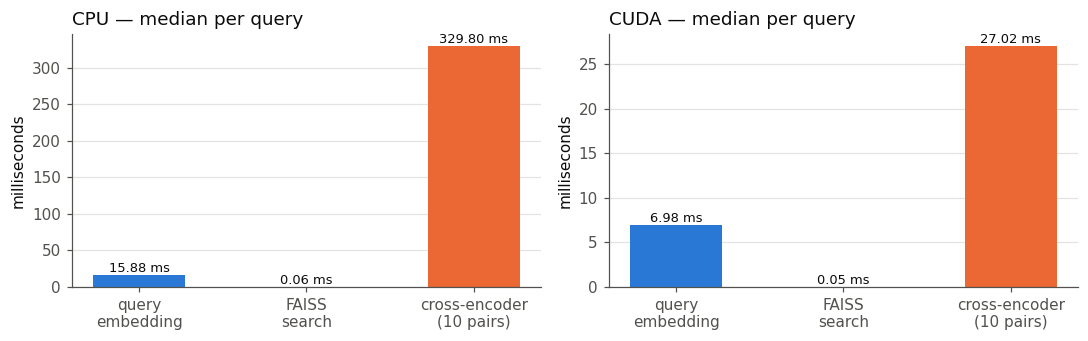

In [19]:
fig, axes = plt.subplots(1, len(latency.index.get_level_values(0).unique()), figsize=(10, 3.2), squeeze=False)
for ax, (device, g) in zip(axes[0], timings.groupby("device")):
    stages = ["embed_ms", "search_ms", "rerank_ms"]
    labels = ["query\nembedding", "FAISS\nsearch", "cross-encoder\n(10 pairs)"]
    medians = [g[s].median() for s in stages]
    bars = ax.bar(labels, medians, color=[BLUE, BLUE, ORANGE], width=0.55)
    for bar, value in zip(bars, medians):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.2f} ms",
                ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_title(f"{device.upper()} — median per query", loc="left", color=INK)
    ax.set_ylabel("milliseconds")
    ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "latency_by_stage.png", bbox_inches="tight"); plt.show()

### Scaling: why not run the cross-encoder over the whole corpus?

Two measured curves:

* **Cross-encoder** — time to score *N* (query, chunk) pairs, for *N* = 10, 100, 1 000 (chunks are
  repeated to reach the larger sizes). One forward pass per pair, so cost grows linearly with *N*.
* **Bi-encoder + exact FAISS search** — one query embedding plus a flat inner-product search over
  *N* random unit vectors, for *N* up to 100 000. The chunk embeddings were computed offline, so only
  the search grows with *N* (and an approximate index such as HNSW would make it sub-linear).

The cross-encoder line is extrapolated linearly to 10⁶ chunks.

In [20]:
def median_ms(fn, repeats=5):
    fn()                                                      # warm-up
    samples = []
    for _ in range(repeats):
        start = time.perf_counter(); fn(); samples.append((time.perf_counter() - start) * 1e3)
    return float(np.median(samples))


probe_q = queries["query"].iloc[0]
texts = [c["text"] for c in chunks]
ce_points = {}
for n in (10, 100, 1000):
    pairs = [(probe_q, texts[i % len(texts)]) for i in range(n)]
    ce_points[n] = median_ms(lambda: cross_encoder.predict(pairs, batch_size=64, show_progress_bar=False))

rng = np.random.default_rng(SEED)
dense_points = {}
for n in (100, 1_000, 10_000, 100_000):
    vectors = rng.standard_normal((n, vector_store.d)).astype("float32")
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
    flat = faiss.IndexFlatIP(vector_store.d); flat.add(vectors)
    dense_points[n] = median_ms(lambda: flat.search(embed([probe_q]), K_CANDIDATES))

per_pair_ms = ce_points[1000] / 1000
scaling = pd.DataFrame({
    "corpus_chunks": [10, 100, 1_000, 10_000, 100_000, 1_000_000],
    "cross_encoder_all_ms": [ce_points.get(n, n * per_pair_ms) for n in (10, 100, 1_000, 10_000, 100_000, 1_000_000)],
    "measured_or_extrapolated": ["measured"] * 3 + ["extrapolated"] * 3,
    "bi_encoder_search_ms": [None, dense_points[100], dense_points[1_000], dense_points[10_000], dense_points[100_000], None],
})
scaling["cross_encoder_all_human"] = scaling["cross_encoder_all_ms"].apply(
    lambda ms: f"{ms:.0f} ms" if ms < 1e3 else (f"{ms/1e3:.1f} s" if ms < 6e4 else f"{ms/6e4:.1f} min"))
display(scaling.round(2))
print(f"cross-encoder cost per pair on {DEVICE}: {per_pair_ms:.3f} ms")
print(f"re-ranking just the top-{K_CANDIDATES}: ~{ce_points[10]:.1f} ms")

,corpus_chunks,cross_encoder_all_ms,measured_or_extrapolated,bi_encoder_search_ms,cross_encoder_all_human
0,10,30.86,measured,NaN,31 ms
1,100,237.67,measured,7.32,238 ms
2,1000,2172.85,measured,7.58,2.2 s
3,10000,21728.50,extrapolated,8.78,21.7 s
4,100000,217284.98,extrapolated,37.11,3.6 min
5,1000000,2172849.80,extrapolated,NaN,36.2 min


cross-encoder cost per pair on cuda: 2.173 ms
re-ranking just the top-10: ~30.9 ms


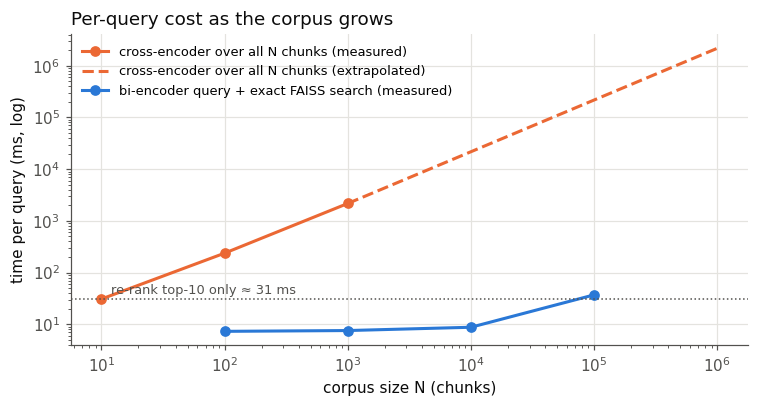

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ce_measured = scaling[scaling.measured_or_extrapolated == "measured"]
ce_extra = scaling[scaling.corpus_chunks >= 1000]
ax.plot(ce_measured.corpus_chunks, ce_measured.cross_encoder_all_ms, color=ORANGE, linewidth=2, marker="o",
        markersize=6, label="cross-encoder over all N chunks (measured)")
ax.plot(ce_extra.corpus_chunks, ce_extra.cross_encoder_all_ms, color=ORANGE, linewidth=2, linestyle="--",
        label="cross-encoder over all N chunks (extrapolated)")
dense = scaling.dropna(subset=["bi_encoder_search_ms"])
ax.plot(dense.corpus_chunks, dense.bi_encoder_search_ms, color=BLUE, linewidth=2, marker="o", markersize=6,
        label="bi-encoder query + exact FAISS search (measured)")
ax.axhline(ce_points[10], color=MUTED, linewidth=1, linestyle=":")
ax.text(12, ce_points[10] * 1.25, f"re-rank top-10 only ≈ {ce_points[10]:.0f} ms", color=MUTED, fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("corpus size N (chunks)"); ax.set_ylabel("time per query (ms, log)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Per-query cost as the corpus grows", loc="left", color=INK)
fig.tight_layout(); fig.savefig(FIGURES / "scaling.png", bbox_inches="tight"); plt.show()

## 12. Export

Everything the report needs is written to `results/`:

| file | contents |
|---|---|
| `chunks.jsonl` | the 105 chunks with section metadata |
| `rank_shift.csv` | per-query gold rank before/after re-ranking and outcome |
| `metrics.csv` | Hit@1, Hit@3, Recall@10, MRR@10 for both pipelines |
| `latency.csv`, `latency_raw.csv`, `scaling.csv` | timing summaries, raw samples, scaling curve |
| `answers.json` | top-3 chunk ids and LLM answers for every query, both pipelines |
| `answer_review.csv` | side-by-side answers with manual verdicts and a note per query |
| `verdict_summary.csv` | verdict counts for Answer 1 vs Answer 2 |
| `figures/*.png` | all plots |

In [22]:
with open(RESULTS / "chunks.jsonl", "w", encoding="utf-8") as f:
    for c in chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
rank_shift.to_csv(RESULTS / "rank_shift.csv")
metrics.to_csv(RESULTS / "metrics.csv")
latency.to_csv(RESULTS / "latency.csv")
timings.to_csv(RESULTS / "latency_raw.csv", index=False)
scaling.to_csv(RESULTS / "scaling.csv", index=False)
(RESULTS / "answers.json").write_text(json.dumps(answer_log, ensure_ascii=False, indent=1), encoding="utf-8")
review_path = RESULTS / "answer_review.csv"
if review_path.exists():                       # keep verdicts that were already filled in
    old = pd.read_csv(review_path, index_col="qid").fillna("")
    for col in ("verdict_1", "verdict_2", "verdict_note"):
        if col in old:
            answers[col] = old[col].reindex(answers.index).fillna("")
answers.to_csv(review_path, encoding="utf-8")

# Manual verdicts (filled in results/answer_review.csv after reading every answer against its reference)
if (answers["verdict_1"] != "").all():
    verdicts = pd.DataFrame({"Answer 1 (baseline)": answers["verdict_1"].value_counts(),
                             "Answer 2 (re-ranked)": answers["verdict_2"].value_counts()}).fillna(0).astype(int)
    verdicts.to_csv(RESULTS / "verdict_summary.csv")
    display(verdicts)
    display(answers.loc[showcase_ids, ["verdict_1", "verdict_2", "verdict_note"]])

print("== SUMMARY ==")
print(f"chunks: {len(chunks)}   queries: {len(queries)}")
display(metrics)
print("outcomes:", rank_shift["outcome"].value_counts().to_dict())
print("showcases:", {qid: f"#{rank_shift.loc[qid, 'baseline_rank']} → #{rank_shift.loc[qid, 'reranked_rank']}" for qid in showcase_ids})

,Answer 1 (baseline),Answer 2 (re-ranked)
correct,17,16
misstated rule,2,2
omitted clause,2,1
refused,11,13


,verdict_1,verdict_2,verdict_note
qid,,,
Q09,refused,correct,Baseline context had s.16/s.17/s.3 only; re-ra...
Q12,correct,refused,Re-ranking pushed the s.15 duties chunk from #...
Q13,omitted clause,correct,Answer 1 built from consent-manager and erasur...
Q21,refused,correct,Re-ranked context included s.6(1) 'limited to ...
Q25,omitted clause,refused,Answer 1 infers deletion from s.8(7) but misse...


== SUMMARY ==
chunks: 105   queries: 32


,Hit@1,Hit@3,Recall@10,MRR@10
pipeline,,,,
Baseline (bi-encoder),0.312,0.562,0.75,0.453
Re-ranked (cross-encoder),0.438,0.656,0.75,0.552


outcomes: {'both hit': 17, 'not retrieved': 8, 'fixed': 4, 'both miss': 2, 'hurt': 1}
showcases: {'Q09': '#5 → #1', 'Q12': '#2 → #7', 'Q13': '#4 → #1', 'Q21': '#4 → #2', 'Q25': '#5 → #3'}
